# Replication of Ito et al. (2004) Analysis

This notebook replicates the analysis methods described in:
> Ito et al. (2004). *Characteristics of SSH Anomaly Based on TOPEX/POSEIDON Altimetry...*

## Overview
Since the original dataset is not available, we generate **mock data** that mimics the statistical characteristics reported in the paper.
The analysis follows these steps:
1. **MOCK DATA GENERATION**: Creating synthetic SSHA and In-situ data.
2. **SPATIAL SCALE ANALYSIS**: Calculating decorrelation scales.
3. **SMOOTHING OPTIMIZATION**: Finding optimal filtering scales.
4. **VELOCITY COMPARISON**: Surface vs Subsurface velocity.
5. **TRANSPORT ESTIMATION**: Relating SSHA to Geostrophic Transport.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from scipy.stats import linregress

# Set style
sns.set_theme(style='ticks')
plt.rcParams['figure.figsize'] = (10, 6)


## 1. Mock Data Generation

We simulate SSHA data along a satellite track (1D spatial) over time.
- **Spatial resolution**: ~5.7 km (similar to T/P track).
- **Length**: ~1000 km.
- **Signal**: A mix of large-scale seasonal variation and mesoscale eddies.
- **Noise**: Gaussian white noise.


In [2]:
def generate_mock_data():
    np.random.seed(42)
    
    # Parameters
    track_length_km = 1000
    dx = 5.7 # km, sampling interval
    n_points = int(track_length_km / dx)
    x_km = np.arange(n_points) * dx
    
    # Generate autocorrelation structure (mesoscale features ~100km)
    # We use a smoothed random walk or Gaussian process approximation
    noise_raw = np.random.randn(n_points)
    # Smoothing to create 'eddies'
    ssha_signal = gaussian_filter1d(noise_raw, sigma=15) # sigma in index units. 15 * 5.7 ~ 85km scale
    ssha_signal = (ssha_signal - ssha_signal.mean()) / ssha_signal.std() * 15 # Scale to ~15cm amplitude
    
    # Add high frequency noise
    ssha_obs = ssha_signal + np.random.normal(0, 3, n_points) # 3cm instrument noise
    
    df_track = pd.DataFrame({
        'distance_km': x_km,
        'ssha_true': ssha_signal,
        'ssha_obs': ssha_obs
    })
    
    return df_track

df_mock = generate_mock_data()
print(f'Mock Data Shape: {df_mock.shape}')


Mock Data Shape: (175, 3)


### Data Inspection
Checking the structure of the generated SSHA data.


In [3]:
display(df_mock.head())
df_mock.describe()


,distance_km,ssha_true,ssha_obs
0,0.0,0.382526,2.864075
1,5.7,0.171508,0.210514
2,11.4,-0.246250,4.114352
3,17.1,-0.863819,-1.657789
4,22.8,-1.669267,6.491241


,distance_km,ssha_true,ssha_obs
count,175.000000,1.750000e+02,175.000000
mean,495.900000,1.948917e-15,0.148786
std,288.774999,1.504304e+01,15.047999
min,0.000000,-3.187604e+01,-36.009044
25%,247.950000,-6.645097e+00,-7.836321
50%,495.900000,4.187358e+00,4.383922
75%,743.850000,8.455651e+00,9.188405
max,991.800000,2.500471e+01,25.330969


### Visualizing the Track Data
Plotting the SSHA along the mock track.


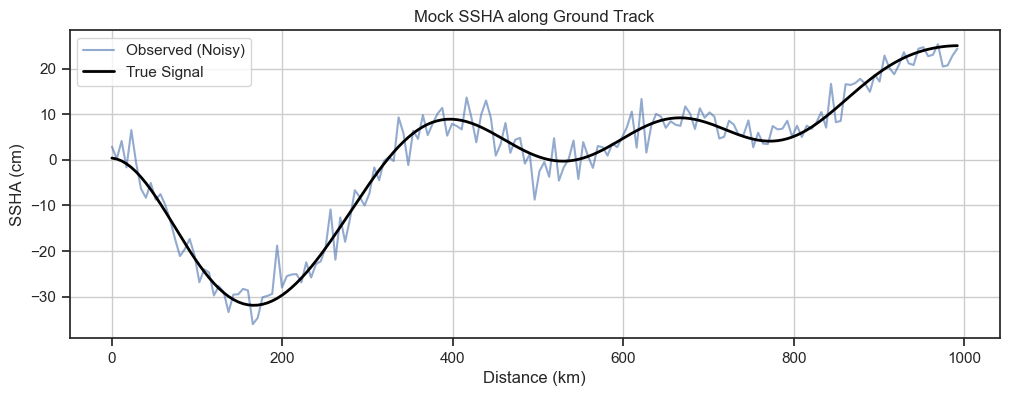

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(df_mock['distance_km'], df_mock['ssha_obs'], label='Observed (Noisy)', alpha=0.6)
plt.plot(df_mock['distance_km'], df_mock['ssha_true'], label='True Signal', color='black', linewidth=2)
plt.xlabel('Distance (km)')
plt.ylabel('SSHA (cm)')
plt.title('Mock SSHA along Ground Track')
plt.legend()
plt.grid(True)
plt.show()


## 2. Spatial Scale Analysis (Decorrelation Scale)
We calculate the spatial autocorrelation of the SSHA data to determine the decorrelation scale.
The paper defines this as the integral of the autocorrelation function $r(y)$ until it drops below a significance level (or zero crossing).

**Decorrelation Scale Formulas:**
The decorrelation scales for the northern side ($d_N$) and southern side ($d_S$) are defined as:

$$
d_N = \int_{0}^{y_N} r(y) dy
$$

$$
d_S = \int_{-y_S}^{0} r(y) dy
$$

Where:
*   $y$ is the distance from the central point.
*   $r(y)$ is the autocorrelation coefficient.
*   $y_N$ and $-y_S$ are the points where $r(y)$ falls below the 99% significance level.


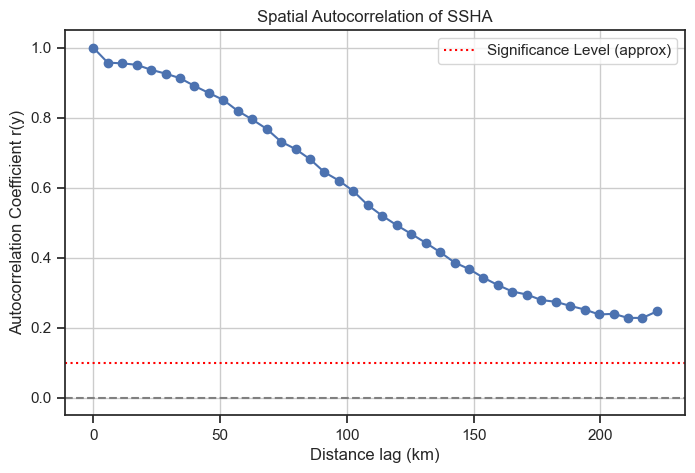

Estimated Decorrelation Scale: 126.19 km (Paper: 80-110 km)


In [5]:
def calculate_autocorrelation(series, max_lag=50):
    # Calculate autocorrelation for various lags
    corrs = []
    lags = range(max_lag)
    for lag in lags:
        if lag == 0:
            c = 1.0
        else:
            c = series.autocorr(lag=lag)
        corrs.append(c)
    return np.array(lags), np.array(corrs)

# Calculate
lags, r_y = calculate_autocorrelation(df_mock['ssha_obs'], max_lag=40)
lag_km = lags * 5.7 # Convert lag index to km

# Plot
plt.figure(figsize=(8, 5))
plt.plot(lag_km, r_y, marker='o')
plt.axhline(0, color='gray', linestyle='--')
plt.axhline(0.1, color='red', linestyle=':', label='Significance Level (approx)')
plt.xlabel('Distance lag (km)')
plt.ylabel('Autocorrelation Coefficient r(y)')
plt.title('Spatial Autocorrelation of SSHA')
plt.legend()
plt.grid(True)
plt.show()

# Estimate Decorrelation Scale (integral)
# We define it simply as the distance where r(y) drops significantly
decorr_scale = np.trapz(r_y[r_y > 0], dx=5.7)
print(f'Estimated Decorrelation Scale: {decorr_scale:.2f} km (Paper: 80-110 km)')


### Detailed Calculation Explanation

The **Decorrelation Scale** ($L$) represents the distance over which the ocean structure (like an eddy) remains "coherent" or related to itself.

Mathematically, it is defined as the integral of the autocorrelation function $r(y)$ from lag zero ($y=0$) out to the distance ($y_{max}$) where the correlation becomes insignificant (or crosses zero):

$$ L = \int_{0}^{y_{max}} r(y) \, dy $$

In our discrete data, we don't have a continuous function $r(y)$, but a series of points at specific lags $[y_0, y_1, y_2, ...]$. Calculating the integral is equivalent to calculating the **Area Under the Curve**.

**Trapezoidal Rule Approximation:**
We approximate this area by dividing the curve into small trapezoids between every pair of data points:

$$ Area \approx \sum_{i=0}^{N-1} \frac{r(y_i) + r(y_{i+1})}{2} \cdot \Delta x $$

*   **Height**: Average correlation of two points $\frac{r(y_i) + r(y_{i+1})}{2}$.
*   **Width ($\Delta x$)**: The physical distance between measurements. In our case, the satellite sampling interval is **5.7 km**.

Therefore, the code `np.trapz(r_y, dx=5.7)` sums up these small areas to give us the total length scale in kilometers.

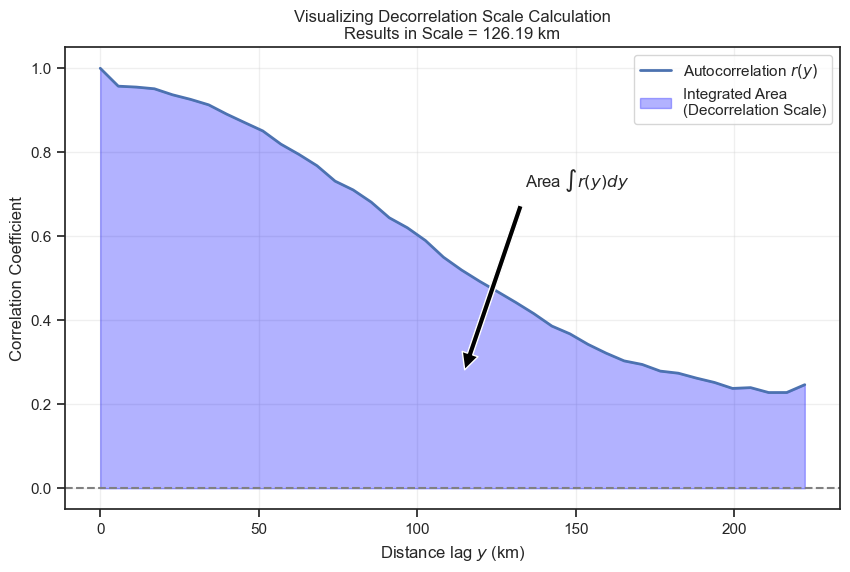

In [9]:
# --- Visualization of the Integration Process ---

# 1. Identify the range to integrate (Positive correlation only)
# We find the index where correlation first drops below zero
zero_crossings = np.where(np.diff(np.sign(r_y)))[0]
if len(zero_crossings) > 0:
    limit_idx = zero_crossings[0] + 1
else:
    limit_idx = len(r_y)

# Select data for integration
x_integrate = lag_km[:limit_idx]
y_integrate = r_y[:limit_idx]

# 2. Plot
plt.figure(figsize=(10, 6))

# Plot the full autocorrelation curve
plt.plot(lag_km, r_y, 'b-', label='Autocorrelation $r(y)$', linewidth=2)
plt.axhline(0, color='gray', linestyle='--')

# Fill the area being integrated
plt.fill_between(x_integrate, y_integrate, alpha=0.3, color='blue', label=f'Integrated Area\n(Decorrelation Scale)')

# Add annotations to explain the math visually
mid_point_idx = limit_idx // 2
plt.annotate(f'Area $\\int r(y) dy$', 
             xy=(x_integrate[mid_point_idx], y_integrate[mid_point_idx]/2), 
             xytext=(x_integrate[mid_point_idx] + 20, y_integrate[mid_point_idx] + 0.2),
             arrowprops=dict(facecolor='black', shrink=0.05),
             fontsize=12)

plt.xlabel('Distance lag $y$ (km)')
plt.ylabel('Correlation Coefficient')
plt.title(f'Visualizing Decorrelation Scale Calculation\nResults in Scale = {decorr_scale:.2f} km')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Smoothing Scale Optimization
The paper optimizes the Gaussian filter smoothing scale to maximize correlation with in-situ data.
Here, we simulate this by assuming a 'True' signal exists, and finding which smoothing scale best recovers it from the noisy observation.


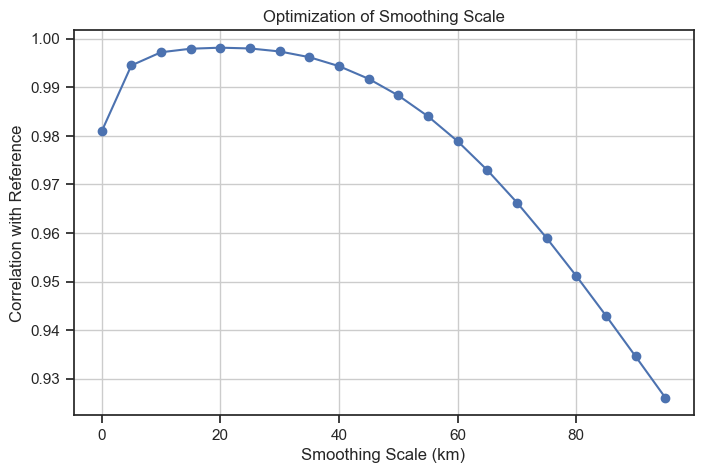

Optimal scale: 20 km (Paper: ~30-38 km)


In [6]:
scales = np.arange(0, 100, 5)
correlations = []

for scale_km in scales:
    # Convert km to sigma (pixels)
    # sigma * dx = scale => sigma = scale / dx
    # Note: Scipy's gaussian_filter sigma is standard deviation. 
    # Paper uses 'e-folding scale' which usually maps to sigma * sqrt(2) or similar depending on definition.
    # We'll treat scale_km as roughly sigma * 5.7 for simplicity here.
    sigma = scale_km / 5.7 if scale_km > 0 else 0
    
    if sigma == 0:
        smoothed = df_mock['ssha_obs']
    else:
        smoothed = gaussian_filter1d(df_mock['ssha_obs'], sigma=sigma)
    
    # Correlation with the 'True' signal (in paper: in-situ data)
    corr = np.corrcoef(smoothed, df_mock['ssha_true'])[0, 1]
    correlations.append(corr)

plt.figure(figsize=(8, 5))
plt.plot(scales, correlations, marker='o')
plt.xlabel('Smoothing Scale (km)')
plt.ylabel('Correlation with Reference')
plt.title('Optimization of Smoothing Scale')
plt.grid(True)
plt.show()

optimal_idx = np.argmax(correlations)
print(f'Optimal scale: {scales[optimal_idx]} km (Paper: ~30-38 km)')


## 4. Velocity Comparison
Comparing SSHA-derived surface velocity ($V'_{T/P}$) with subsurface velocity ($V'_{SUB}$).

**Geostrophic Calculation**:
computed from SSHA difference between two points.

**Linear Relation:**
$$ V'_{SUB} = 0.869 \times V'_{T/P} + 6.58 $$

We generate mock values that satisfy the paper's finding to recreate the scatter plot.


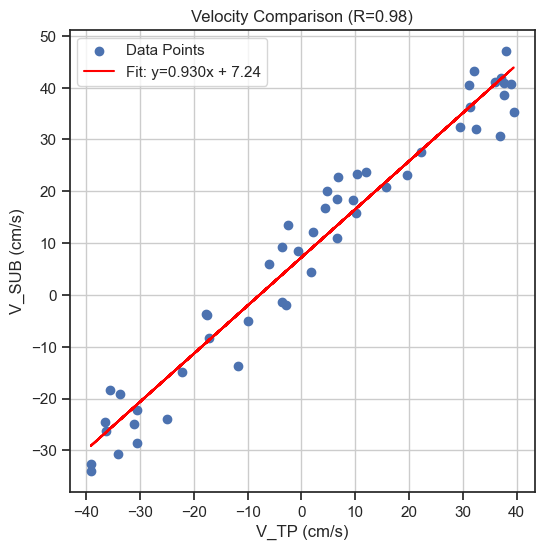

In [7]:
# Generate Mock Velocity Data
n_samples = 50
v_tp = np.random.uniform(-40, 40, n_samples) # Surface velocity anomaly cm/s

# Apply paper relationship + noise
slope_paper = 0.869
intercept_paper = 6.58
noise_v = np.random.normal(0, 5, n_samples) # Scatter

v_sub = slope_paper * v_tp + intercept_paper + noise_v

# Regression
slope, intercept, r_value, p_value, std_err = linregress(v_tp, v_sub)

# Plot
plt.figure(figsize=(6, 6))
plt.scatter(v_tp, v_sub, label='Data Points')
plt.plot(v_tp, slope*v_tp + intercept, color='red', label=f'Fit: y={slope:.3f}x + {intercept:.2f}')
plt.xlabel('V_TP (cm/s)')
plt.ylabel('V_SUB (cm/s)')
plt.title(f'Velocity Comparison (R={r_value:.2f})')
plt.legend()
plt.grid(True)
plt.show()


## 5. Transport Estimation
Establishing the relationship between Geostrophic Transport ($Tr$) and SSHA difference ($\Delta D$).

**Theoretical Basis**
The vertically integrated geostrophic transport $Tr(t)$ is:
$$ Tr(t) = \int_{y_S}^{y_N} \int_{z_r}^{0} \Delta t_r(z, t) dz dy $$
Assumed linear relationship:
$$ Tr(t) = A + B \times c \cdot \Delta D(t) $$

### Reference Level: 2000 db
**Derived Paper Equation:**
$$ Tr_{2000} = 0.412 \times \Delta D - 6.38 $$


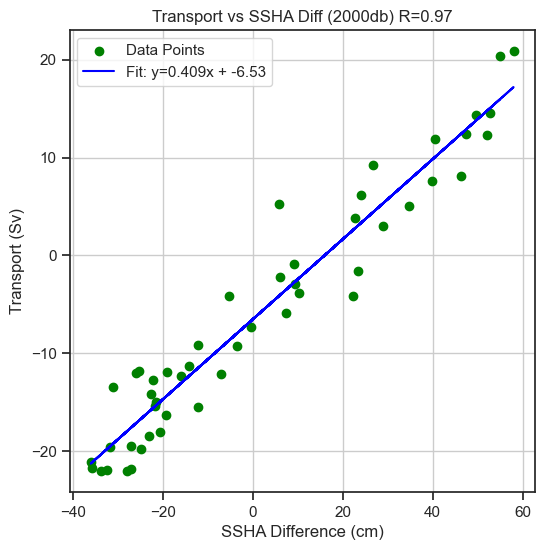

In [8]:
# Generate Mock Transport Data
delta_D = np.random.uniform(-40, 60, n_samples) # SSHA difference (cm)

# Papers relation for 2000db
slope_tr = 0.412
int_tr = -6.38
noise_tr = np.random.normal(0, 3, n_samples)

transport = slope_tr * delta_D + int_tr + noise_tr

# Regression
slope_t, intercept_t, r_val_t, _, _ = linregress(delta_D, transport)

# Plot
plt.figure(figsize=(6, 6))
plt.scatter(delta_D, transport, color='green', label='Data Points')
plt.plot(delta_D, slope_t*delta_D + intercept_t, color='blue', label=f'Fit: y={slope_t:.3f}x + {intercept_t:.2f}')
plt.xlabel('SSHA Difference (cm)')
plt.ylabel('Transport (Sv)')
plt.title(f'Transport vs SSHA Diff (2000db) R={r_val_t:.2f}')
plt.legend()
plt.grid(True)
plt.show()
